In [1]:
import sys
sys.path.append('../scripts')
from OracleCUSUM import CUSUM
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def detection_delay_vs_effect_size(
    mu0=0.0, sigma0=1.0, sigma1=1.0, 
    effect_sizes=np.linspace(0.2, 3.0, 10), 
    num_trials=50, threshold=5.0, stream_length=300, changepoint=50
):
    delays = []

    for delta in effect_sizes:
        mu1 = mu0 + delta
        f0 = lambda x: norm.pdf(x, loc=mu0, scale=sigma0)
        f1 = lambda x: norm.pdf(x, loc=mu1, scale=sigma1)
        detector = CUSUM(f0_pdf=f0, f1_pdf=f1, threshold=threshold)
        delay_list = []

        for _ in range(num_trials):
            pre_change = np.random.normal(mu0, sigma0, size=changepoint)
            post_change = np.random.normal(mu1, sigma1, size=stream_length - changepoint)
            stream = np.concatenate([pre_change, post_change])
            _, _, tau = detector.run(stream)
            if tau is not None and tau > changepoint:
                delay_list.append(tau - changepoint)

        avg_delay = np.mean(delay_list) if delay_list else np.nan
        delays.append(avg_delay)

    return effect_sizes, delays

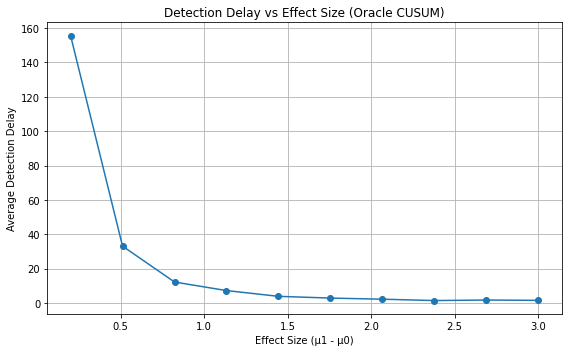

In [2]:
# Run and plot
effect_sizes, avg_delays = detection_delay_vs_effect_size()

plt.figure(figsize=(8, 5))
plt.plot(effect_sizes, avg_delays, marker='o')
plt.xlabel("Effect Size (μ1 - μ0)")
plt.ylabel("Average Detection Delay")
plt.title("Detection Delay vs Effect Size (Oracle CUSUM)")
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/dd_effect_size.png", dpi=300, bbox_inches='tight')
plt.show()